# 大模型微调 06：GPT-2 医疗问诊机器人与物流 RAG

本篇整理所有 `06` 开头资料，包含物流行业 RAG 回顾，以及基于 GPT-2 搭建医疗问诊机器人的数据预处理、模型配置、训练验证和生成流程。

> 医疗项目资料记录的是模型训练和数据工程流程，不把模型输出当作真实医疗诊断。


## 一、物流行业 RAG 回顾

通用 LLM 主要依赖历史训练数据，无法自动获得企业私有知识或最新物流状态。RAG 的做法是把本地文档转换为向量，提问时检索相关片段，再把片段和问题一起交给 LLM 生成答案。

```text
加载 PDF → 文本分割 → Embedding → FAISS 向量库
用户问题 → 问题向量化 → top-k 检索 → 上下文 Prompt → Qwen2.5 生成
```


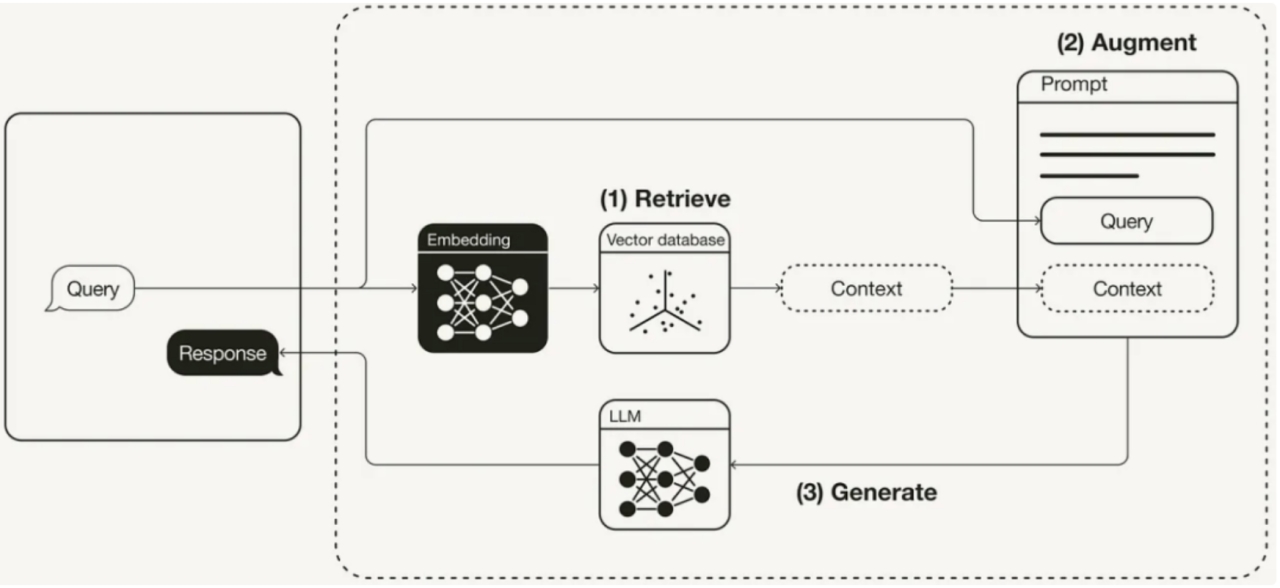

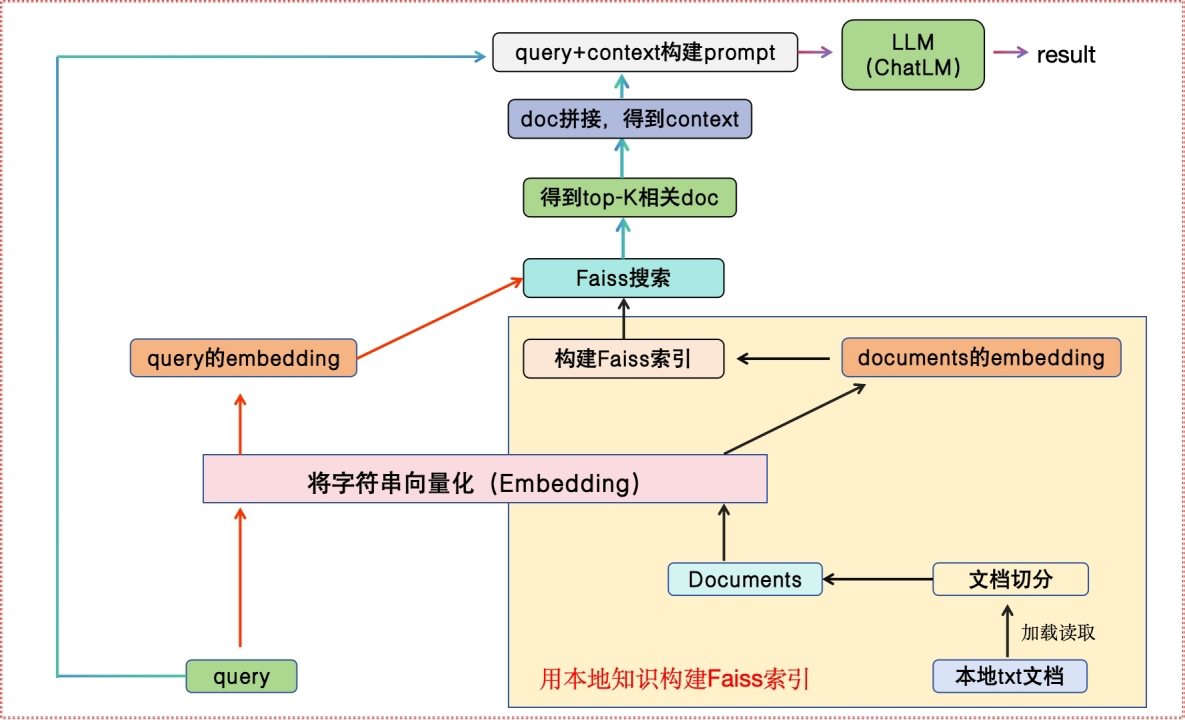

项目环境要求 Python 3.8–3.11，并安装 `faiss-cpu`、`langchain`、`ollama`。本地运行需要准备 `qwen2.5:7b` 和 `mxbai-embed-large`。知识库构建代码依次完成 PDF 加载、递归切分、向量化和 FAISS 持久化。


```python
from langchain_community.document_loaders import PyMuPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_community.embeddings import OllamaEmbeddings
from langchain_community.vectorstores import FAISS # 向量数据库


def get_vector():
    # 第一步：加载文档
    loader = PyMuPDFLoader("物流信息.pdf")
    # 将文本转成 Document 对象
    data = loader.load()
    print(f'data-->{data}')
    print(f'len(data):{len(data)}')

    # # 第二步：切分文本
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=50, chunk_overlap=20)
    # # 切割加载的 document
    split_docs = text_splitter.split_documents(data)
    print("split_docs size:", len(split_docs))
    print(split_docs)
    #
    # # 第三步：初始化 hugginFace 的 embeddings 对象
    embeddings = OllamaEmbeddings(model="mxbai-embed-large")
    #
    #
    # # 第四步：将 document通过embeddings对象计算得到向量信息并永久存入FAISS向量数据库，用于后续匹配查询
    db = FAISS.from_documents(split_docs, embeddings)
    db.save_local("./faiss/wuliu")

if __name__ == '__main__':
    result = get_vector()
```

检索问答阶段用 `similarity_search(question, k=2)` 找到相关片段，把它们放入 Prompt，并要求模型只基于已知内容回答；Web 版本用 `ConversationalRetrievalChain` 和 Streamlit 保存多轮历史。


```python
# coding:utf-8
# 导入必备的工具包
import time
from local_db import *
from langchain import PromptTemplate
from langchain_community.llms import Ollama


# 加载FAISS向量库
embeddings = OllamaEmbeddings(model="mxbai-embed-large", temperature=0)
db = FAISS.load_local("faiss/wuliu", embeddings, allow_dangerous_deserialization=True)
# db = FAISS.load_local("faiss/wuliu", embeddings)

start_time = time.time()


def get_related_content(related_docs):
    # print(f'related_docs--》{related_docs}')
    related_content = []
    for doc in related_docs:
        # print(f'doc.page_content--》{doc.page_content}')
        related_content.append(doc.page_content.replace("\n\n", "\n"))
    # print(f'related_content列表状态--》{related_content}')

    return "\n".join(related_content)


def define_prompt():
    question = '我的快递出发地是哪？预计几天的时间到达？'
    docs = db.similarity_search(question, k=2)

    related_content = get_related_content(docs)
    # print('*' * 80)
    # print(f'related_content字符串状态-->{related_content}')
    # print('*'*80)
    PROMPT_TEMPLATE = """
        基于以下已知信息，简洁和专业的来回答用户的问题。不允许在答案中添加编造成分。
        已知内容:
        {context}
        问题:
        {question}"""

    prompt = PromptTemplate(
        input_variables=["context", "question"],
        template=PROMPT_TEMPLATE,)

    my_pmt = prompt.format(context=related_content,
                           question=question)

    return my_pmt


def qa():
    model = Ollama(model="qwen2.5:7b")
    # print(f'model-->{model}')
    my_pmt = define_prompt()
    print(f'my_pmt--》{my_pmt}')
    # result = model.invoke(my_pmt)
    # return result



if __name__ == '__main__':
    result = qa()
    print(result)
    end_time = time.time()
    print(end_time-start_time)
```

```python
from local_qa import *
# ConversationalRetrievalChain作用：自动保存历史对话信息
from langchain.chains import ConversationalRetrievalChain
import streamlit as st

# 设置标题
st.set_page_config(page_title="物流行业信息咨询系统")
st.title("物流行业信息咨询RAG系统")

# 初始化全局变量
chat_history = []


# 定义检索链函数
def new_retrival():
    """
    创建基于 ConversationalRetrievalChain 的问答链。
    """
    chain = ConversationalRetrievalChain.from_llm(
        llm=Ollama(model="qwen2.5:7b"),  # 使用本地大模型
        retriever=db.as_retriever()        # 基于本地数据库的检索器
    )
    return chain

# 主逻辑
def main():
    """
    Streamlit 主页面的交互逻辑。
    """
    # print(f'st.session_state-->{st.session_state}')
    # 初始化会话状态
    if "messages" not in st.session_state:
        st.session_state.messages = []  # 用于保存聊天记录
    # print(f'st.session_state-->{st.session_state}')
    # 展示历史聊天记录
    for message in st.session_state.messages:
        # print(f'message["role"]-->{message["role"]}')
        with st.chat_message(message["role"]):
            st.markdown(message["content"])  # 显示消息内容

    # 接受用户输入
    # prompt = st.chat_input("请输入你的问题:")
    if prompt := st.chat_input("请输入你的问题:"):
        # 保存用户消息到会话状态
        print(f'prompt--》{prompt}')
        st.session_state.messages.append({"role": "user", "content": prompt})

        # 显示用户输入
        with st.chat_message("user"):
            st.markdown(prompt)

        # 调用模型获取回答
        with st.chat_message("assistant"):
            # 占位符用于显示逐字生成的回答
            message_placeholder = st.empty()
            full_response = ""

            # 调用检索链获取答案
            chain = new_retrival()
            result = chain.invoke({"question": prompt, "chat_history": chat_history})
            print(f'result--->{result}')
            chat_history.append((prompt, result["answer"]))  # 更新聊天历史
            assistant_response = result["answer"]
            message_placeholder.markdown(assistant_response)

            # 保存回答到会话状态
            st.session_state.messages.append({"role": "assistant", "content": assistant_response})

# 运行主逻辑
if __name__ == "__main__":
    main()

```

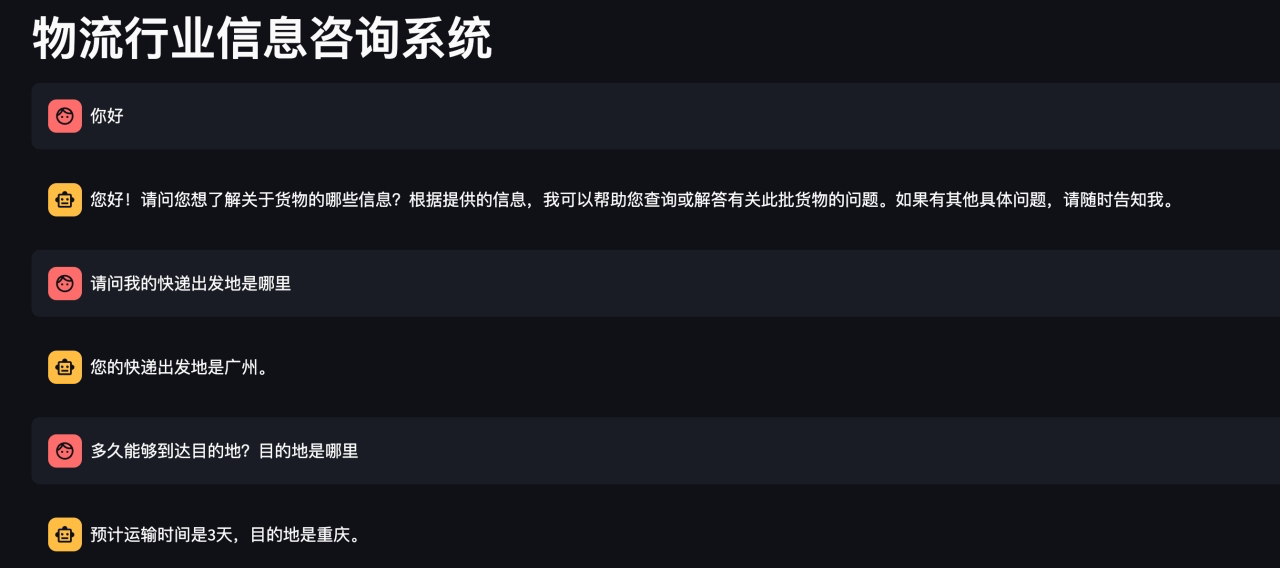

## 二、医疗问诊机器人项目

项目目标是使用医疗对话语料训练一个 GPT-2 问答机器人。资料 PDF 给出的环境为 Python 3.6、`transformers==4.2.0`、`pytorch==1.7.0`。

模型结构为：词嵌入 + 位置嵌入 → 12 层 Transformer Decoder → LayerNorm + 线性语言模型头。主要配置是 `n_embd=768`、`n_head=12`、`n_layer=12`、`n_positions=1024`。


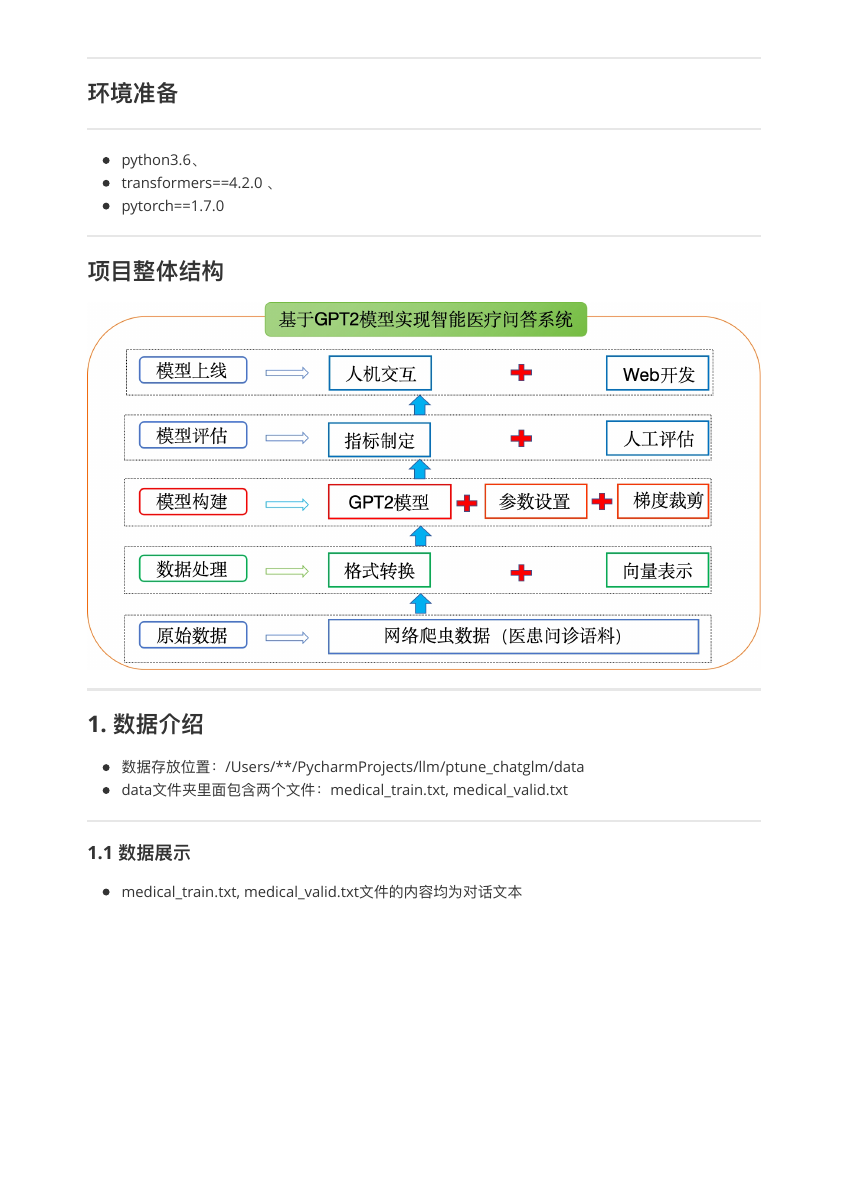

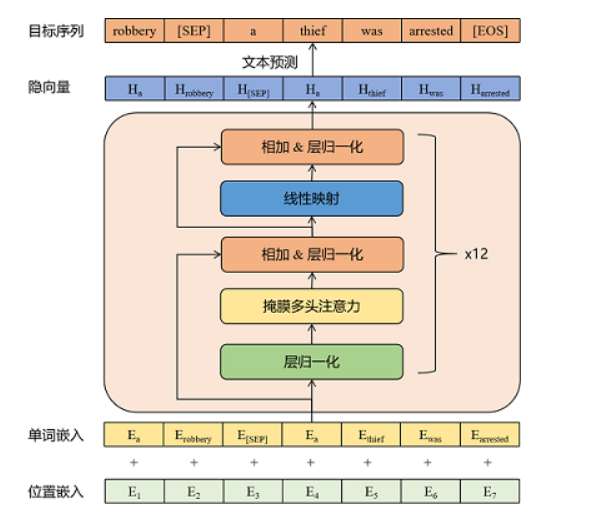

### 2.1 数据集与对话格式

`06-附属资料/data` 中包含 `medical_train.txt` 和 `medical_valid.txt`。每段对话由多行 utterance 组成，段落之间用空行分隔，多轮对话可以在同一段落中继续追加多条语句。

示例：

```text
小孩五岁，脐周淋巴结肿大……怎么办呀？
你好，考虑肠系膜淋巴结炎……及时的对症治疗即可
```

资料 PDF 记载训练集约 91487 条、验证集约 1244 条；按当前文本文件的空行切分会得到更少的对话块，这是统计口径不同造成的。


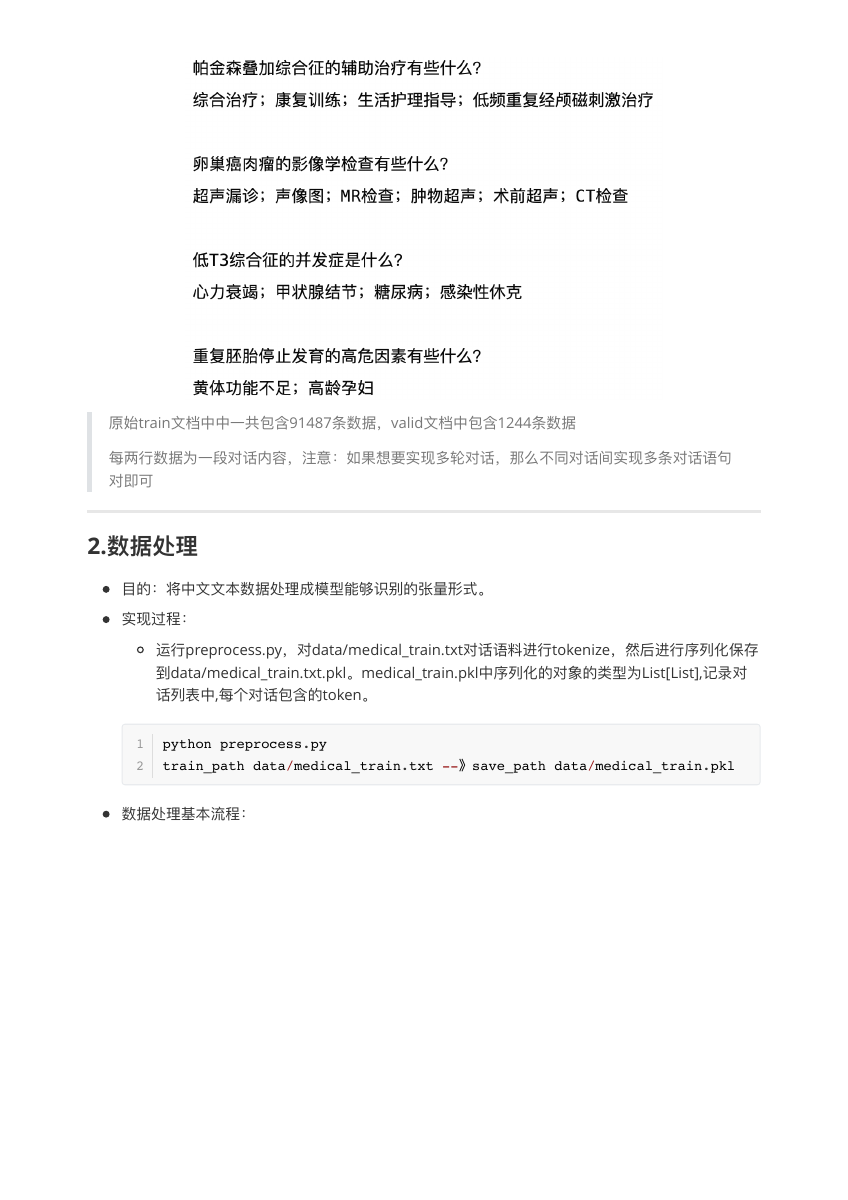

## 三、文本预处理

每段对话统一为：

```text
[CLS] utterance1 [SEP] utterance2 [SEP] utterance3 [SEP]
```

`[CLS]` 标记对话开始，`[SEP]` 分隔 utterance，`[PAD]` 补齐 batch，`[UNK]` 表示词表外 token。`preprocess.py` 使用本地 `BertTokenizerFast` 词表，按换行符切分对话，tokenize 后用 pickle 保存 `List[List[int]]`。


```python
from transformers import BertTokenizerFast, BertTokenizer
import pickle # 保存pkl文件的命令
from tqdm import tqdm # 加在进度条
import os


def data_preprocess(train_txt_path, train_pkl_path):
    """
    对原始语料进行tokenizer，将每段对话处理成如下形式："[CLS]sentence1[SEP]sentence2[SEP]sentence3[SEP]"
    """

    # 初始化tokenizer，使用BertTokenizerFast从预训练的中文Bert模型（bert-base-chinese）创建一个tokenizer对象
    # tokenizer = BertTokenizerFast.from_pretrained('/Users/ligang/PycharmProjects/llm/prompt_tasks/bert-base-chinese',
    #                                         )

    tokenizer = BertTokenizerFast('/Users/ligang/PycharmProjects/llm/Gpt2_Chatbot/vocab/vocab.txt',
                                                  sep_token="[SEP]",
                                                  pad_token="[PAD]",
                                                  cls_token="[CLS]")


    print(f'tokenizer.vocab_size-->{tokenizer.vocab_size}')

    sep_id = tokenizer.sep_token_id  # 获取分隔符[SEP]的token ID
    cls_id = tokenizer.cls_token_id  # 获取起始符[CLS]的token ID
    print(f'sep_id-->{sep_id}')
    print(f'cls_id-->{cls_id}')
    # #
    #
    # # 读取训练数据集
    with open(train_txt_path, 'rb') as f:
        data = f.read().decode("utf-8")  # 以UTF-8编码读取文件内容
    # print(data)
    # # # # # 根据换行符区分不同的对话段落，需要区分Windows和Linux\mac环境下的换行符
    if "\r\n" in data:
        train_data = data.split("\r\n\r\n")
    else:
        train_data = data.split("\n\n")
    # #
    print(len(train_data))  # 打印对话段落数量
    print(train_data[:2])
    # # # # # 开始进行tokenize
    # # # # # 保存所有的对话数据,每条数据的格式为："[CLS]seq1[SEP]seq2[SEP]seq3[SEP]"
    dialogue_len = []  # 记录所有对话tokenize分词之后的长度，用于统计中位数与均值
    dialogue_list = []  # 记录所有对话
    # # # # #
    for index, dialogue in enumerate(tqdm(train_data)):
        # print(f'dialogue-->{dialogue}')
        if "\r\n" in dialogue:
            sequences = dialogue.split("\r\n")
        else:
            sequences = dialogue.split("\n")
        # print(f'sequences--》{sequences}')

        input_ids = [cls_id]  # 每个dialogue以[CLS]seq1[sep]seq2[sep]
        for sequence in sequences:

            input_ids += tokenizer.encode(sequence, add_special_tokens=False)  # 将每个对话句子进行tokenize，并将结果拼接到input_ids列表中
            # input_ids += tokenizer.encode(sequence)  # 将每个对话句子进行tokenize，并将结果拼接到input_ids列表中
            input_ids.append(sep_id)  # 每个seq之后添加[SEP]，表示seqs会话结束

        dialogue_len.append(len(input_ids))  # 将对话的tokenize后的长度添加到对话长度列表中
        dialogue_list.append(input_ids)  # 将tokenize后的对话添加到对话列表中

    # # # # 保存数据
    with open(train_pkl_path, "wb") as f:
        pickle.dump(dialogue_list, f)


if __name__ == '__main__':
    train_txt_path = '../data/medical_valid.txt'
    train_pkl_path = '../data/medical_valid.pkl'
    data_preprocess(train_txt_path, train_pkl_path)

```

### 3.1 Dataset 与 DataLoader

`MyDataset` 根据 `max_len=300` 截断序列并转换为 `torch.long`。`collate_fn` 用 `pad_sequence` 把不同长度样本补齐：输入使用 `padding_value=0`，标签使用 `padding_value=-100`。

`-100` 是交叉熵常用的 `ignore_index`，补齐位置不参与 loss 和准确率统计。


```python
# -*- coding: utf-8 -*-
from torch.utils.data import Dataset  # 导入Dataset模块，用于定义自定义数据集
import torch  # 导入torch模块，用于处理张量和构建神经网络
import pickle


class MyDataset(Dataset):
    """
    自定义数据集类，继承自Dataset类
    """
    def __init__(self, input_list, max_len):
        super().__init__()
        """
        初始化函数，用于设置数据集的属性
        :param input_list: 输入列表，包含所有对话的tokenize后的输入序列
        :param max_len: 最大序列长度，用于对输入进行截断或填充
        """
        # print(f'input_list--->{len(input_list)}')
        self.input_list = input_list  # 将输入列表赋值给数据集的input_list属性
        self.max_len = max_len  # 将最大序列长度赋值给数据集的max_len属性

    def __len__(self):
        """
        获取数据集的长度
        :return: 数据集的长度
        """
        return len(self.input_list)  # 返回数据集的长度

    def __getitem__(self, index):
        """
        根据给定索引获取数据集中的一个样本
        :param index: 样本的索引
        :return: 样本的输入序列张量
        """
        # print(f'当前取出的索引是--》{index}')
        input_ids = self.input_list[index]  # 获取给定索引处的输入序列
        # print(f'input_ids--》{input_ids}')
        input_ids = input_ids[:self.max_len]  # 根据最大序列长度对输入进行截断或填充
        input_ids = torch.tensor(input_ids, dtype=torch.long)  # 将输入序列转换为张量long类型
        return input_ids  # 返回样本的输入序列张量

if __name__ == '__main__':
    with open('../data/medical_train.pkl', "rb") as f:
        train_input_list = pickle.load(f)  # 从文件中加载输入列

    # print(f'train_input_list-->{len(train_input_list)}')
    # # print(f'train_input_list-->{type(train_input_list)}')
    # print(f'train_input_list-->{train_input_list[0]}')
    mydataset = MyDataset(input_list=train_input_list, max_len=300)
    print(f'mydataset-->{len(mydataset)}')
    result = mydataset[0]
    print(result)
```

```python
# -*- coding: utf-8 -*-
import torch.nn.utils.rnn as rnn_utils  # 导入rnn_utils模块，用于处理可变长度序列的填充和排序
from torch.utils.data import Dataset, DataLoader  # 导入Dataset和DataLoader模块，用于加载和处理数据集
import torch  # 导入torch模块，用于处理张量和构建神经网络
import pickle  # 导入pickle模块，用于序列化和反序列化Python对象
from dataset import *  # 导入自定义的数据集类
from parameter_config import *

params = ParameterConfig()

def load_dataset(train_path, valid_path):
    # print('进入函数')
    """
    加载训练集和验证集
    :param train_path: 训练数据集路径
    :return: 训练数据集和验证数据集
    """
    with open(train_path, "rb") as f:
        train_input_list = pickle.load(f)  # 从文件中加载输入列表

    with open(valid_path, "rb") as f:
        valid_input_list = pickle.load(f)  # 从文件中加载输入列表
    # 划分训练集与验证集
    # print(len(train_input_list))  # 打印输入列表的长度
    # print(train_input_list[0])
    #
    train_dataset = MyDataset(train_input_list, params.max_len)  # 创建训练数据集对象
    val_dataset = MyDataset(valid_input_list, params.max_len)  # 创建验证数据集对象
    return train_dataset, val_dataset  # 返回训练数据集和验证数据集

def collate_fn(batch):
    """
    自定义的collate_fn函数，用于将数据集中的样本进行批处理
    :param batch: 样本列表
    :return: 经过填充的输入序列张量和标签序列张量
    """
    # print(f'batch-->{batch}')
    # print(f'batch的长度-->{len(batch)}')
    # print(f'batch的第一个样本的长度--》{batch[0].shape}')
    # print(f'batch的第二个样本的长度--》{batch[1].shape}')
    # print(f'batch的第三个样本的长度--》{batch[2].shape}')
    # print(f'batch的第四个样本的长度--》{batch[3].shape}')
    # print(f'*'*80)
    #rnn_utils.pad_sequence：将根据一个batch中，最大句子长度，进行补齐
    input_ids = rnn_utils.pad_sequence(batch, batch_first=True, padding_value=0)  # 对输入序列进行填充，使其长度一致
    # print(f'batch的第一个样本的长度--》{input_ids[0].shape}')
    # print(f'batch的第二个样本的长度--》{input_ids[1].shape}')
    # print(f'batch的第三个样本的长度--》{input_ids[2].shape}')
    # print(f'batch的第四个样本的长度--》{input_ids[3].shape}')
    labels = rnn_utils.pad_sequence(batch, batch_first=True, padding_value=-100)  # 对标签序列进行填充，使其长度一致
    # # print(f'labels-->{labels}')
    return input_ids, labels  # 返回经过填充的输入序列张量和标签序列张量


def get_dataloader(train_path, valid_path):
    """
    获取训练数据集和验证数据集的DataLoader对象
    :param train_path: 训练数据集路径
    :return: 训练数据集的DataLoader对象和验证数据集的DataLoader对象
    """

    train_dataset, val_dataset = load_dataset(train_path, valid_path)  # 加载训练数据集和验证数据集
    # print(f'train_dataset-->{len(train_dataset)}')
    # print(f'val_dataset-->{len(val_dataset)}')
    train_dataloader = DataLoader(train_dataset,
                                  batch_size=params.batch_size,
                                  shuffle=True,
                                  collate_fn=collate_fn,
                                  drop_last=True)  # 创建训练数据集的DataLoader对象
    validate_dataloader = DataLoader(val_dataset,
                                     batch_size=params.batch_size,
                                     shuffle=True,
                                     collate_fn=collate_fn,
                                     drop_last=True)  # 创建验证数据集的DataLoader对象
    return train_dataloader, validate_dataloader  # 返回训练数据集的DataLoader对象和验证数据集的DataLoader对象


if __name__ == '__main__':
    train_dataloader, validate_dataloader = get_dataloader(params.train_path, params.valid_path)
    for input_ids, labels in train_dataloader:
        print(f'input_ids--》{input_ids.shape}')
        print(f'labels--》{labels.shape}')
        break

```

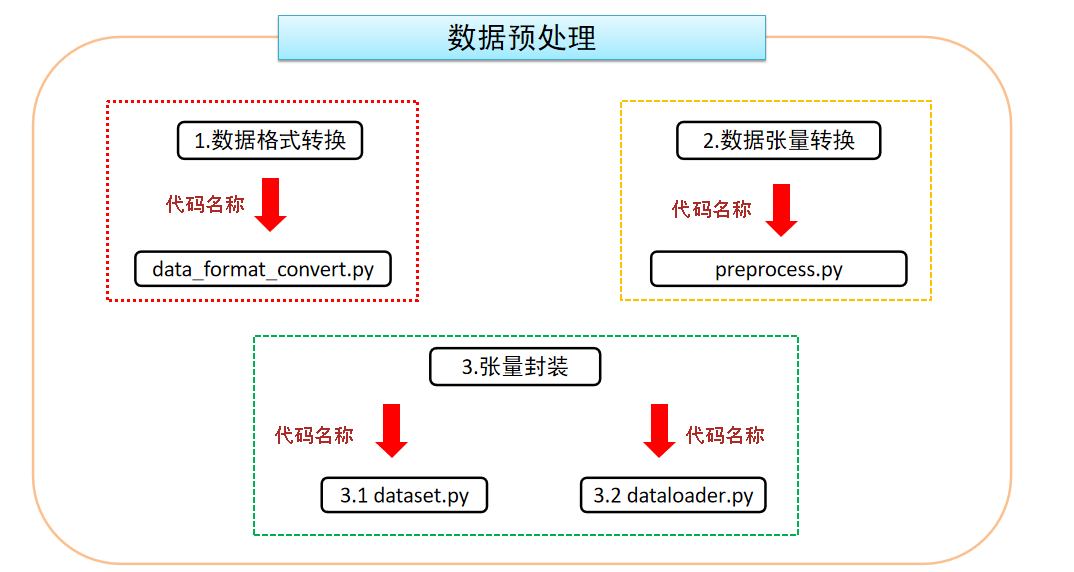

## 四、GPT-2 配置与训练参数

`config.json` 的关键字段：

| 参数 | 值 |
| --- | ---: |
| `model_type` | `gpt2` |
| `n_embd` | 768 |
| `n_head` | 12 |
| `n_layer` | 12 |
| `n_positions` / `n_ctx` | 1024 |
| `vocab_size` | 13317 |
| 激活函数 | `gelu_new` |
| dropout | 0.1 |

`parameter_config.py` 还配置了 `batch_size=8`、`epochs=4`、`lr=2.6e-5`、`max_len=300`、梯度累积 4 步、梯度裁剪 2.0、warmup 100 步和 `ignore_index=-100`。词表大小必须和 tokenizer、模型输出层保持一致。


```json
{
  "activation_function": "gelu_new",
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "gradient_checkpointing": false,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 12,
  "n_positions": 1024,
  "output_past": true,
  "resid_pdrop": 0.1,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 400
    }
  },
  "tokenizer_class": "BertTokenizer",
  "transformers_version": "4.2.0",
  "use_cache": true,
  "vocab_size": 13317
}

```

```python
#-*- coding: utf-8 -*-
import torch

class ParameterConfig():
    def __init__(self):
        # 判断是否使用GPU（1.电脑里必须有显卡；2.必须安装cuda版本的pytorch）
        # 下载cuda版本的pytorch链接：https://pytorch.org/get-started/previous-versions/
        # self.device = torch.device('mps' if torch.cuda.is_available() else 'cpu')
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        # 词典路径：在vocab文件夹里面
        self.vocab_path = './vocab/vocab.txt'
        # 训练文件路径
        self.train_path = 'data/medical_train.pkl'
        # 验证数据文件路径
        self.valid_path = 'data/medical_valid.pkl'
        # 模型配置文件
        self.config_json = 'config/config.json'
        # 模型保存路径
        self.save_model_path = 'save_model1'
        # 如果你有预训练模型就写上路径（我们本次没有直接运用GPT2预训练好的模型，而是仅只用了该模型的框架）
        self.pretrained_model = ''
        # 保存对话语料
        self.save_samples_path = '/Users/ligang/PycharmProjects/LLM/Gpt2_Chatbot/sample'
        # 忽略一些字符：句子需要长度补齐，针对补的部分，没有意义，所以一般不进行梯度更新
        self.ignore_index = -100
        # 历史对话句子的长度
        self.max_history_len = 3# "dialogue history的最大长度"
        # 每一个完整对话的句子最大长度
        self.max_len = 300  # '每个utterance的最大长度,超过指定长度则进行截断,默认25'
        self.repetition_penalty = 10.0 # "重复惩罚参数，若生成的对话重复性较高，可适当提高该参数"
        self.topk = 4 #'最高k选1。默认8'
        self.batch_size = 8 #一个批次几个样本
        self.epochs = 4 # 训练几轮
        self.loss_step = 1 # 多少步汇报一次loss
        self.lr = 2.6e-5
        # eps，为了增加数值计算的稳定性而加到分母里的项，其为了防止在实现中除以零
        self.eps = 1.0e-09
        self.max_grad_norm = 2.0
        self.gradient_accumulation_steps = 4
        # 默认.warmup_steps = 4000
        self.warmup_steps = 100 # 使用Warmup预热学习率的方式,即先用最初的小学习率训练，然后每个step增大一点点，直到达到最初设置的比较大的学习率时（注：此时预热学习率完成），采用最初设置的学习率进行训练（注：预热学习率完成后的训练过程，学习率是衰减的），有助于使模型收敛速度变快，效果更佳。


if __name__ == '__main__':
    pc = ParameterConfig()
    print(pc.train_path)
    print(pc.device)
    print(torch.cuda.device_count())
```

## 五、训练与验证

训练阶段对每个 batch：

1. 将 `input_ids`、`labels` 移到设备；
2. 调用 `model.forward(input_ids, labels=labels)` 得到 logits 和 loss；
3. 按梯度累积步数反向传播；
4. 用 `clip_grad_norm_` 防止梯度爆炸；
5. 更新 AdamW 和 warmup 学习率；
6. 统计非 `ignore_index` token 的准确率；
7. 按 epoch 保存模型。

验证阶段使用 `torch.no_grad()` 计算平均 loss。资料说明验证 loss 最低不一定意味着生成效果最好，仍需用实际对话检查。


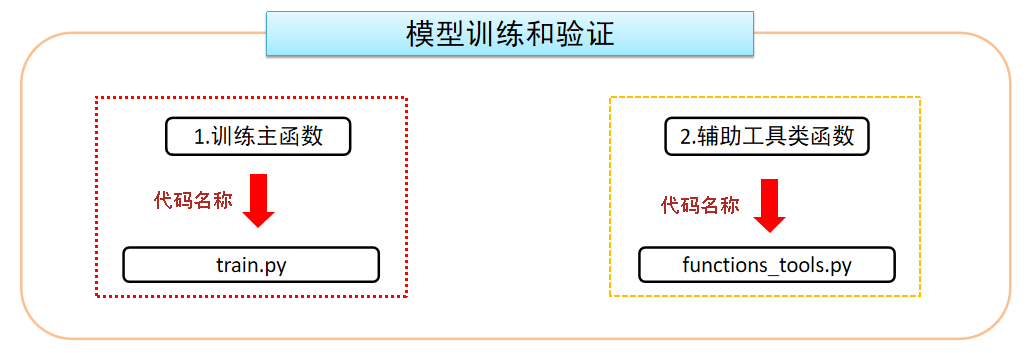

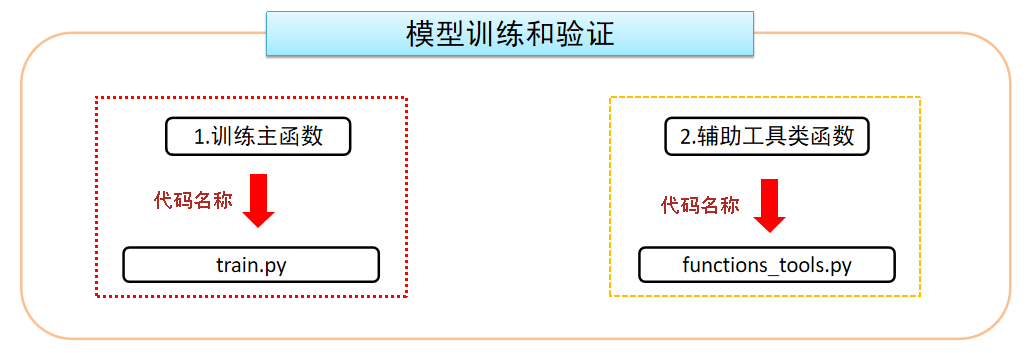

## 六、模型生成与多轮交互

交互流程是：加载 tokenizer 和 GPT-2 → 保留最近若干轮历史 → 拼接 `[CLS]`、历史 utterance、`[SEP]` → 逐 token 生成 → 遇到 `[SEP]` 停止 → 保存聊天记录。

生成参数中，`max_history_len=3` 限制历史长度，`repetition_penalty=10.0` 降低重复 token 概率，`topk=4` 限制候选 token。Top-k 保留概率最高的 k 个 token，Top-p 按累计概率保留候选，过滤后使用 `torch.multinomial` 采样。


## 七、代码目录和数据文件

| 路径 | 作用 |
| --- | --- |
| `06-代码/data_preprocess/preprocess.py` | tokenizer、特殊 token 拼接、pickle 保存 |
| `06-代码/data_preprocess/dataset.py` | 截断并封装 Dataset |
| `06-代码/data_preprocess/dataloader.py` | batch 补齐、DataLoader |
| `06-附属资料/parameter_config.py` | 设备、路径、训练超参数 |
| `06-附属资料/config/config.json` | GPT-2 结构配置 |
| `06-附属资料/data/medical_train.txt` | 训练语料 |
| `06-附属资料/data/medical_valid.txt` | 验证语料 |
| `06-附属资料/vocab/vocab.txt` | tokenizer 词表 |


## 八、排查顺序

- 检查 Python、PyTorch、Transformers 版本与课件一致；
- 确认 tokenizer 词表路径、`vocab_size` 和 GPT-2 输出层匹配；
- 先运行预处理，确认 `.pkl` 生成；
- 打印样本 token、`input_ids.shape`、`labels.shape` 检查补齐；
- 确认 `labels=-100` 不参与 loss 和 accuracy；
- 训练前检查 GPU、显存、batch、max length 和梯度累积；
- 生成时限制历史长度，确认 `[SEP]` 能结束回复。


## 九、本章总结

- RAG 通过检索私有知识补充通用 LLM，核心是切分、向量化、FAISS 检索和上下文 Prompt。
- 医疗问诊项目把多轮对话统一为 `[CLS]... [SEP]` 序列，再通过 Dataset、DataLoader 送入 GPT-2。
- 输入补齐使用 0，标签补齐使用 -100，后者不会参与交叉熵和准确率。
- GPT-2 的配置、词表、最大长度和预处理结果必须保持一致。
- 训练看 loss、token accuracy 和验证 loss，生成看历史长度、重复惩罚、top-k/top-p 和终止 token。
